<a href="https://colab.research.google.com/github/m-hefnawy/network-design-lecture/blob/main/network_design_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A Hands-on Introduction to Network Design Optimization

<h3>05.11.2026<br>
Tiago de Morais Montanher, PhD, CAP<br>
Head of Operations Research at Minerva Foods<br>
</h3>

## About Minerva Foods

<img src="https://companieslogo.com/img/orig/BEEF3.SA_BIG-9402c43a.png" alt="Minerva Foods logo" width="320">

Minerva Foods is a Brazilian food company founded in 1924 and headquartered in Barretos (São Paulo state). It is listed on B3 under the ticker **BEEF3** and is a leader in South America in the production and sale of fresh beef, live cattle exports and beef by-products. It also processes lamb and sells processed foods.

| | 2025 figure | Source |
|---|---|---|
| **Workforce** | more than 30,000 employees | Minerva Foods 2025 results release, 18 Mar 2026 [1] |
| **Net revenue** | R\$ 54.8 billion, a record and +60.9% vs. 2024 | [1] |
| **Gross revenue** | R\$ 58.0 billion, of which **60% from exports** | [1] |
| **EBITDA** | R\$ 4.8 billion, an 8.8% margin | [1] |
| **Footprint** | 46 industrial units, 23 distribution centers, 18 international offices | [1] |
| **Countries with operations** | Brazil, Paraguay, Argentina, Uruguay, Colombia, Chile and Australia (7 countries) | [1], [2] |
| **Countries it distributes to** | more than 100 countries on five continents | [1], [3] |

**Sources**
1. Minerva Foods, *Minerva Foods reports record net revenue of R\$ 54.8 billion in 2025*, PR Newswire, 18 March 2026. <https://tools.prnewswire.com/en-us/live/20823/release/20260318EN14157>
2. Minerva Foods, *The Company*. <https://www.minervafoods.com/en/the-company/> (accessed 29 Oct 2026)
3. Minerva Foods Investor Relations, *History and Corporate Profile*. <https://ri.minervafoods.com/en/history-and-corporate-profile/> (accessed 29 Oct 2026)


All data, examples and code in this lecture are not related to Minerva Foods or any other company. Examples and data are ficticious and for the purpose of this presentation only!

## Agenda

1. [Target Audience and Pre-requisites](#sec-1)
    - [1.1 Target Audience](#sec-1-1)
    - [1.2 Pre-requisites](#sec-1-2)
2. [What do we cover in this Lecture](#sec-2)
3. [Use case: Greenfield Analysis](#sec-3)
    - [3.1 Problem Statement](#sec-3-1)
    - [3.2 Reading data and selecting relevant information](#sec-3-2)
    - [3.3 Visualizing data](#sec-3-3)
    - [3.4 Pre-processing](#sec-3-4)
    - [3.5 A first answer: the center of gravity](#sec-3-5)
    - [3.6 Building the basic optimization model](#sec-3-6)
    - [3.7 Running the basic model](#sec-3-7)
    - [3.8 How to read the SCIP log](#sec-3-8)
    - [3.9 Center of gravity vs. optimization](#sec-3-9)
    - [3.10 Enforcing SLAs](#sec-3-10)
    - [3.11 Balancing costs and SLAs](#sec-3-11)
    - [3.12 Conclusion](#sec-3-12)
    - [3.13 Open questions](#sec-3-13)
4. [Further Reading](#sec-4)

<a id="sec-1"></a>
# 1. Target Audience and Pre-requisites

<a id="sec-1-1"></a>
## 1.1 Target Audience

- **Analysts, data scientists and engineers** who want to move from descriptive analytics to *decision* models.
- **Supply chain and logistics professionals** who want to understand what happens inside a network design tool.
- **Students** of operations research, industrial engineering or computer science who know the theory and want to see it applied end to end.

No previous experience with optimization solvers is needed. We build every model from scratch.

<a id="sec-1-2"></a>
## 1.2 Pre-requisites

**Knowledge**
- How to clone a repository on Github (https://github.com/montanhe/network-design-lecture)
- Basic Python: functions, lists, dictionaries, and a first contact with `pandas`.
- High-school algebra: sums, inequalities and the idea of minimizing a function.

**Software** (Python 3.10 or newer)

```bash
pip install pyscipopt pandas openpyxl numpy matplotlib folium random-land-points jupyter
```

- [`pyscipopt`](https://github.com/scipopt/PySCIPOpt) is the Python interface to **SCIP**, the open-source mixed-integer programming solver we use throughout ([SCIP](#ref-scip)). The pip wheel already ships SCIP, so no separate installation is needed.
- `folium` draws the interactive maps, and `openpyxl` lets `pandas` read the Excel input files.
- [`random-land-points`](https://github.com/duncaneddy/random-land-points) samples random points on land inside a country, using the Natural Earth borders. We use it to generate candidate warehouse sites.

**Files**
Put these files in the **same folder as this notebook**:
- `customers.xlsx`: the customers of the case study.
- `placement.png` and `facility.png`: the illustrations used in the notebook.

Run the next cell to check your installation.

In [1]:
from importlib.metadata import PackageNotFoundError, version


def check_packages(packages: list[str]) -> dict[str, str]:
    """Return the installed version of each package, or 'MISSING' when it is not installed."""
    versions: dict[str, str] = {}
    for package in packages:
        try:
            versions[package] = version(package)
        except PackageNotFoundError:
            versions[package] = "MISSING"
    return versions


for package, installed in check_packages(["pyscipopt", "pandas", "openpyxl", "numpy", "matplotlib", "folium", "random-land-points"]).items():
    print(f"{package:<19} {installed}")

pyscipopt           6.3.0
pandas              2.2.3
openpyxl            3.1.5
numpy               2.4.6
matplotlib          3.10.0
folium              0.20.0
random-land-points  1.1.0


In [2]:
%pip install random-land-points

In [3]:
%pip install pyscipopt

<a id="sec-2"></a>
# 2. What do we cover in this Lecture

## Introduction to Network Design Optimization

Let us agree on what *network design* means and why it deserves our attention.

**What is network design?**
- A supply chain network is the set of **facilities** (plants, warehouses, distribution centers) and the **flows** of goods between them and the customers they serve.
- *Network design* answers the strategic questions: **how many** facilities should we have, **where** should they be, and **which customers** should each of them serve?
- Watson et al. (2013) describe it as the discipline of using optimization to find the network structure that best balances cost and service ([Watson et al., 2013](#ref-watson)).

**Why does it matter?**
- Network decisions lock in a large share of the total logistics cost for years. Facilities are expensive to open and to close.
- They also set the **service level**: the distance from a warehouse to a customer drives delivery time and the ability to meet SLAs.
- Small improvements in the network structure often translate into savings that operational tuning alone cannot reach.

**Why optimization?**
- Even a small problem has an enormous number of combinations: with 20 candidate sites there are more than one million ways to choose which ones to open.
- Mixed-integer programming lets us describe the business rules precisely and lets a solver, such as **SCIP** ([SCIP](#ref-scip)), search that space for us. [Wolsey, 2020](#ref-wolsey) is the classic textbook on how this works.
- Want to feel it before we code it? The [Gurobi, Burrito Optimization Game](#ref-burrito) asks you to place food trucks by hand and then shows the optimal plan: a facility location problem in disguise.

**The problem at the heart of this lecture: warehouse placement**
- We have a set of **customers**, each with a location and a demand.
- We have a set of **candidate sites** where a warehouse could be opened, each with a fixed opening cost.
- We decide which sites to open and assign every customer to one open warehouse, so that **fixed costs plus transportation costs** are as low as possible, while respecting service constraints.

![The warehouse placement problem](https://github.com/m-hefnawy/network-design-lecture/blob/main/placement.png?raw=1)

### Lecture roadmap

We follow the path of every real network design project:

| Step | Question | Where |
|---|---|---|
| **Business problem** | What must we decide, and how do we measure a good decision? | 3.1 |
| **Data** | What do we know about customers, sites and costs? Is it clean? | 3.2 to 3.4 |
| **Heuristic baseline** | What would a spreadsheet answer look like? | 3.5 |
| **Mathematical model** | Sets, parameters, variables, constraints, objective | 3.6 |
| **Code** | One typed, documented Python function per constraint and per objective term | 3.6 |
| **Solve and read the log** | Did the solver prove optimality? How good is the answer? | 3.7, 3.8 |
| **Scenarios and trade-offs** | What does an extra point of service cost? | 3.10, 3.11 |
| **Communicate** | Maps, KPIs and charts that a manager understands | 3.9 |

**The use case: a greenfield analysis.** A (ficticious) company enters Germany and must decide where to place its distribution centers. We compare the classic *center of gravity* with an *optimization model*, and we study the trade-off between cost and service level (SLA).

<a id="sec-3"></a>
# 3. Use case: Greenfield Analysis

## Introduction to Greenfield Analysis

Imagine we could design our distribution network from scratch, with no existing warehouses, leases or habits to respect. That thought experiment is called a **greenfield analysis**, and it is where this hands-on part begins.

**What is a greenfield analysis?**
- A greenfield analysis designs the network on a **blank map**: existing facilities are ignored, and warehouses may be placed wherever they serve the customers best.
- The only inputs are essentially **where the demand is** and **how much** of it there is, plus a few cost and service assumptions.

**Why is it useful?**
- It gives an **ideal benchmark**: the gap between the greenfield cost and today's cost tells us how much the legacy network is costing us.
- It is the natural starting point when we **enter a new market**, such as a new country or customer segment.
- It answers strategic questions quickly: *How many warehouses do we really need? In which regions should they be?*

**How does it work in its simplest form?**
- The classic starting point is the **center of gravity**: the demand-weighted average of customer locations. With one warehouse, it minimizes the demand-weighted *squared* distance to the customers.
- With several warehouses, we split customers into groups and place one warehouse at the center of gravity of each group, repeating until the groups stop changing.
- These continuous locations are then refined with **candidate sites** and an optimization model, which is exactly what we build in the next sections.

**What should we keep in mind?**
- A greenfield point may fall in a lake, a forest or a city center with no warehouse space. It shows *a region*, not an address.
- Straight-line distances ignore the road network, and the model ignores real-estate, labor and tax differences between regions.
- Greenfield results are a **compass, not a map**: they show the direction, and the detailed model decides the destination.

In the rest of this section we follow these steps on a concrete case: we frame the problem, prepare the data, compute the center of gravity, and then build and solve an optimization model with SCIP.

<a id="sec-3-1"></a>
## 3.1 Problem Statement

**The business situation**
- A company is starting its operations in **Germany**.
- As the **supply chain manager**, you have the task of determining the **location of a distribution center (DC)** to serve potential customers.
- The decision must consider two factors: **operational cost** and **service level**.

**What we are given**
- A list of **50 potential customers** (`customers.xlsx`, next to this notebook), each with its location, its yearly demand in tons and its required service time (SLA: 2, 4 or 8 hours).
- A logistics cost of **1 € per ton and per kilometer** from the distribution center to the customers.
- An average truck speed of **90 km per hour**, plus **1 hour** of handling before the truck leaves.

**What we must deliver**
- The **best location** for the distribution center.
- The **average yearly operational cost** of serving the customers from this distribution center.
- The **average service level** achieved from this distribution center.
- Later in the section: what it would cost to serve **every** customer within its SLA.

**Assumptions we will make along the way**
- We start with one single distribution center serving all customers, and relax this in 3.10 and 3.11.
- The demand in the dataset is the **yearly** demand of each customer, in tons.
- The delivery time is 1 hour of handling plus the distance divided by 90 km/h. A customer is **served on time** when this time is within its SLA.
- Distances are straight-line (great-circle) distances between the DC and each customer.

**Guiding questions for you**
- Where on the map would you place the distribution center, before running any model?
- Is the cheapest location also the one with the best service level?

<a id="sec-3-2"></a>
## 3.2 Reading data and selecting relevant information

- The customer file is deliberately simple: one row per customer with five columns, `CustomerId`, `Latitude`, `Longitude`, `Demand` (tons per year) and `SLA` (hours).
- A good habit is to **validate** the data as early as possible. `load_customers` (setup cell below) checks that the five columns exist and stops with a clear message if a demand or an SLA is not positive.
- The two numbers that drive the model are the **demand** and the **SLA**. Note the pattern in the table below: the **largest customers have the tightest SLA** (2 hours). That will matter a lot.

### Setup: imports, assumptions and helper functions

The next cell holds everything the analysis needs: the imports, the business assumptions, and small helper functions to load data and compute distances. Every function is **typed** and **documented**, so you can read its contract without reading its body.

> **About the assumptions.** The delivery time to a customer is **1 hour** of handling (`HANDLING_TIME_H`) plus the distance divided by an average truck speed of **90 km/h**. With SLAs of 2, 4 and 8 hours, a DC can therefore serve a customer on time only within 90, 270 or 630 km. Change these numbers and re-run the notebook to see how much the answer depends on them.

In [4]:
from __future__ import annotations

import random
from dataclasses import dataclass
from pathlib import Path
from typing import Literal

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random_land_points as rlp
from IPython.display import Image, display
from pyscipopt import Expr, Model, Variable, quicksum

# ----- Business assumptions -------------------------------------------------------------
COST_PER_TON_KM: float = 1.0   # € per ton and per km, from the DC to the customer
TRUCK_SPEED_KMH: float = 90.0  # average truck speed
HANDLING_TIME_H: float = 1.0    # handling time before the truck leaves (0 = driving time only)
EARTH_RADIUS_KM: float = 6371.0

# ----- Input files and folders: everything lives next to this notebook -----------------
CUSTOMERS_FILE: Path = Path("customers.xlsx")
FIGURES_DIR: Path = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

# ----- Chart colors ---------------------------------------------------------------------
BLUE, ORANGE, AQUA, GREY, RED = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#e34948"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "axes.axisbelow": True, "axes.edgecolor": "#8a8984", "font.size": 10})

CUSTOMER_COLUMNS: list[str] = ["CustomerId", "Latitude", "Longitude", "Demand", "SLA"]  # Demand in t/year, SLA in hours


def read_table(path: Path) -> pd.DataFrame:
    """Read the first sheet of an Excel file that sits in the notebook's folder."""
    if not path.exists():
        raise FileNotFoundError(f"{path.name} was not found in {Path.cwd()}: put it in the same folder as this notebook")
    return pd.read_excel(path)


def load_customers(path: Path) -> pd.DataFrame:
    """Load the customer table, keep the columns the models need and index it by CustomerId.

    Raises a ValueError when a required column is missing or when a demand or SLA is not positive.
    """
    raw = read_table(path)
    missing = set(CUSTOMER_COLUMNS) - set(raw.columns)
    if missing:
        raise ValueError(f"{path.name} is missing the columns {sorted(missing)}")
    customers = raw[CUSTOMER_COLUMNS].set_index("CustomerId")
    if (customers["Demand"] <= 0).any() or (customers["SLA"] <= 0).any():
        raise ValueError("Every customer needs a positive demand and a positive SLA")
    return customers


def haversine_km(lat1: np.ndarray | float, lon1: np.ndarray | float,
                 lat2: np.ndarray | float, lon2: np.ndarray | float) -> np.ndarray:
    """Great-circle distance in km between points given in decimal degrees (broadcasts like numpy)."""
    lat1, lon1, lat2, lon2 = (np.radians(np.asarray(v, dtype=float)) for v in (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(a))


def lead_time_h(distance_km: np.ndarray | float, speed_kmh: float = TRUCK_SPEED_KMH,
                handling_h: float = HANDLING_TIME_H) -> np.ndarray:
    """Door-to-door lead time in hours: handling time plus driving time."""
    return handling_h + np.asarray(distance_km, dtype=float) / speed_kmh

print(f"Input file: {CUSTOMERS_FILE} (same folder as this notebook)")
for sla in (2, 4, 8):
    print(f"An SLA of {sla} h allows at most {(sla - HANDLING_TIME_H) * TRUCK_SPEED_KMH:.0f} km between the DC and the customer")

Input file: customers.xlsx (same folder as this notebook)
An SLA of 2 h allows at most 90 km between the DC and the customer
An SLA of 4 h allows at most 270 km between the DC and the customer
An SLA of 8 h allows at most 630 km between the DC and the customer


In [5]:
customers = load_customers(CUSTOMERS_FILE)
print(f"Loaded {len(customers)} customers from {CUSTOMERS_FILE}")
display(customers.head())


def summarize_by_sla(customers: pd.DataFrame) -> pd.DataFrame:
    """Number of customers, total demand and share of demand for each SLA class."""
    summary = customers.groupby("SLA").agg(Customers=("Demand", "size"), Demand_t=("Demand", "sum"))
    summary["Share of demand"] = summary["Demand_t"] / summary["Demand_t"].sum()
    return summary


display(summarize_by_sla(customers).style.format({"Demand_t": "{:,.0f}", "Share of demand": "{:.0%}"}))
print(f"Total yearly demand: {customers['Demand'].sum():,.0f} t")

Loaded 50 customers from customers.xlsx


,Latitude,Longitude,Demand,SLA
CustomerId,,,,
Customer01,52.5200,13.4050,1200,2
Customer02,53.5511,9.9937,950,2
Customer03,48.1351,11.5820,880,2
Customer04,50.9375,6.9603,640,2
Customer05,50.1109,8.6821,560,2


,Customers,Demand_t,Share of demand
SLA,,,
2,9,"5,850",46%
4,29,"5,415",43%
8,12,"1,440",11%


Total yearly demand: 12,705 t


<a id="sec-3-3"></a>
## 3.3 Visualizing data

- Each **blue circle** is a customer, and the number inside it is its yearly **demand in tons**.
- Hover over a circle to see the **customer ID**, the **demand** and the **SLA**.
- Before optimizing anything, look for **clusters**: the Rhine-Ruhr area concentrates many customers, while the largest single customers sit in Berlin, Hamburg, Munich, Cologne and Frankfurt, far apart from each other.

In [6]:
def plot_customer_map(customers: pd.DataFrame) -> folium.Map:
    """Interactive map with one circle per customer, sized and labeled by its yearly demand."""
    m = folium.Map(location=[customers["Latitude"].mean(), customers["Longitude"].mean()], zoom_start=6)
    for customer_id, r in customers.iterrows():
        size = 24
        folium.Marker(
            [r["Latitude"], r["Longitude"]],
            icon=folium.DivIcon(
                icon_size=(size, size), icon_anchor=(size // 2, size // 2),
                html=(f'<div style="width:{size}px;height:{size}px;border-radius:50%;'
                      f'background:rgba(42,120,214,0.75);border:1px solid #1b4f8a;color:white;'
                      f'font-size:10px;font-weight:bold;display:flex;align-items:center;justify-content:center">'
                      f'{r["Demand"]:.0f}</div>'),
            ),
            tooltip=f"<b>{customer_id}</b><br>Demand: {r['Demand']:.0f} t/year<br>SLA: {r['SLA']} h",
        ).add_to(m)
    return m


plot_customer_map(customers)

<a id="sec-3-5"></a>
## 3.5 A first answer: the center of gravity

- We place the distribution center at the **demand-weighted average** of the customer coordinates.
- We then measure the two indicators from the problem statement:
    - **Operational cost** = Σ demand (t) × distance (km) × 1 €/(t·km), per year.
    - **Service level** = share of customers (and of demand) whose lead time is within their SLA.
- `evaluate_assignment` computes these KPIs for *any* assignment of customers to sites. We reuse it for every solution in the notebook, so all methods are measured with the same ruler.

In [7]:
def center_of_gravity(points: np.ndarray, weights: np.ndarray) -> np.ndarray:
    """Weighted average of (lat, lon) points: the location that minimizes the weighted squared distance."""
    return (points * weights[:, None]).sum(axis=0) / weights.sum()


def weighted_kmeans(points: np.ndarray, weights: np.ndarray, k: int,
                    iterations: int = 100, n_starts: int = 20, seed: int = 0) -> tuple[np.ndarray, np.ndarray]:
    """Multi-facility center of gravity (demand-weighted k-means).

    Alternates between assigning every point to its closest center and moving each center to the
    center of gravity of its group. Keeps the best of `n_starts` random starts.
    Returns the centers (k x 2) and the group index of every point.
    """
    rng = np.random.default_rng(seed)
    best: tuple[float, np.ndarray, np.ndarray] | None = None
    for _ in range(n_starts):
        centers = points[rng.choice(len(points), size=k, replace=False, p=weights / weights.sum())]
        for _ in range(iterations):
            group = np.linalg.norm(points[:, None] - centers[None], axis=2).argmin(axis=1)
            centers = np.array([center_of_gravity(points[group == j], weights[group == j])
                                if (group == j).any() else centers[j] for j in range(k)])
        sse = float((weights * ((points - centers[group]) ** 2).sum(axis=1)).sum())
        if best is None or sse < best[0]:
            best = (sse, centers, group)
    return best[1], best[2]


In [8]:
def evaluate_assignment(customers: pd.DataFrame, sites: pd.DataFrame, assignment: dict[str, str],
                        demand_factor: float = 1.0) -> tuple[pd.DataFrame, dict[str, float]]:
    """Cost and service KPIs of serving each customer from its assigned site.

    `sites` must hold Latitude and Longitude indexed by site id; `assignment` maps customer id -> site id.
    Returns one row per customer with distance, cost, lead time and on-time flag, plus a KPI dictionary.
    """
    out = customers.copy()
    out["Demand"] = out["Demand"] * demand_factor
    out["Site"] = [assignment[i] for i in out.index]
    out["Distance_km"] = haversine_km(out["Latitude"], out["Longitude"],
                                      sites.loc[out["Site"], "Latitude"].to_numpy(),
                                      sites.loc[out["Site"], "Longitude"].to_numpy())
    out["Cost_EUR"] = out["Demand"] * out["Distance_km"] * COST_PER_TON_KM
    out["Lead_time_h"] = lead_time_h(out["Distance_km"])
    out["On_time"] = out["Lead_time_h"] <= out["SLA"]
    kpis = {
        "DCs": float(out["Site"].nunique()),
        "Transport cost (M€/year)": out["Cost_EUR"].sum() / 1e6,
        "Cost per ton (€/t)": out["Cost_EUR"].sum() / out["Demand"].sum(),
        "Average distance (km)": out["Distance_km"].mean(),
        "Max distance (km)": out["Distance_km"].max(),
        "Service level, customers (%)": 100 * out["On_time"].mean(),
        "Service level, demand (%)": 100 * out.loc[out["On_time"], "Demand"].sum() / out["Demand"].sum(),
    }
    return out, kpis


def plot_solution_map(detail: pd.DataFrame, sites: pd.DataFrame, zoom_start: int = 6) -> folium.Map:
    """Map an assignment: green customers are on time, red ones are late; lines go to their site."""
    used = sites.loc[detail["Site"].unique()]
    m = folium.Map(location=[detail["Latitude"].mean(), detail["Longitude"].mean()], zoom_start=zoom_start)
    for customer_id, r in detail.iterrows():
        site = sites.loc[r["Site"]]
        color = AQUA if r["On_time"] else RED
        folium.PolyLine([[site["Latitude"], site["Longitude"]], [r["Latitude"], r["Longitude"]]],
                        color=color, weight=0.8, opacity=0.6).add_to(m)
        folium.CircleMarker(
            [r["Latitude"], r["Longitude"]], radius=2 + np.sqrt(r["Demand"]) / 3, color=color, weight=1,
            fill=True, fill_opacity=0.7,
            tooltip=(f"{customer_id}<br>{r['Demand']:.0f} t/year, {r['Distance_km']:.0f} km<br>"
                     f"{r['Lead_time_h']:.1f} h vs SLA {r['SLA']} h: {'on time' if r['On_time'] else 'late'}"),
        ).add_to(m)
    for site_id, s in used.iterrows():
        load = detail.loc[detail["Site"] == site_id, "Demand"].sum()
        folium.Marker([s["Latitude"], s["Longitude"]], tooltip=f"<b>{site_id}</b><br>{load:,.0f} t/year",
                      icon=folium.Icon(color="darkblue", icon="warehouse", prefix="fa")).add_to(m)
    return m


coords = customers[["Latitude", "Longitude"]].to_numpy()
cog_lat, cog_lon = center_of_gravity(coords, customers["Demand"].to_numpy(float))
cog_site = pd.DataFrame({"Latitude": [cog_lat], "Longitude": [cog_lon]}, index=pd.Index(["Center of gravity"], name="SiteId"))
cog_detail, cog_kpis = evaluate_assignment(customers, cog_site, {i: "Center of gravity" for i in customers.index})

print(f"Distribution center (center of gravity): lat {cog_lat:.4f}, lon {cog_lon:.4f}\n")
display(pd.Series(cog_kpis, name="Center of gravity").to_frame().style.format("{:,.1f}"))
plot_solution_map(cog_detail, cog_site)

Distribution center (center of gravity): lat 51.1059, lon 9.6076



,Center of gravity
DCs,1.0
Transport cost (M€/year),2.9
Cost per ton (€/t),229.1
Average distance (km),217.0
Max distance (km),372.2
"Service level, customers (%)",70.0
"Service level, demand (%)",46.3


### More than one DC: the multi-facility center of gravity

- With several DCs, we split the customers into groups and place one DC at the center of gravity of each group, repeating until the groups stop changing. This is a **demand-weighted k-means**.
- The map shows the single-DC center of gravity and a three-DC design. Use the layer control in the top-right corner to switch between them.
- Keep this picture in mind: in 3.9 we compare it with the optimization model.

In [9]:
def plot_greenfield_preview(customers: pd.DataFrame, k: int = 3) -> folium.Map:
    """Map the customers, the single-DC center of gravity and a k-DC center-of-gravity design."""
    coords = customers[["Latitude", "Longitude"]].to_numpy()
    demand = customers["Demand"].to_numpy(dtype=float)
    cog = center_of_gravity(coords, demand)
    centers, group = weighted_kmeans(coords, demand, k=k)

    m = folium.Map(location=cog.tolist(), zoom_start=6)
    demand_layer = folium.FeatureGroup(name="Customers (size = demand)")
    for (lat, lon), customer_id, tons in zip(coords, customers.index, demand):
        folium.CircleMarker([lat, lon], radius=2 + np.sqrt(tons) / 3, color=BLUE, weight=1,
                            fill=True, fill_opacity=0.6, tooltip=f"{customer_id}: {tons:.0f} t").add_to(demand_layer)
    demand_layer.add_to(m)

    one_wh = folium.FeatureGroup(name="Greenfield: 1 warehouse (center of gravity)")
    for lat, lon in coords:
        folium.PolyLine([[lat, lon], cog.tolist()], color=GREY, weight=0.6, opacity=0.6).add_to(one_wh)
    folium.Marker(cog.tolist(), tooltip=f"Center of gravity ({cog[0]:.2f}, {cog[1]:.2f})",
                  icon=folium.Icon(color="red", icon="warehouse", prefix="fa")).add_to(one_wh)
    one_wh.add_to(m)

    k_wh = folium.FeatureGroup(name=f"Greenfield: {k} warehouses", show=False)
    for (lat, lon), j in zip(coords, group):
        folium.PolyLine([[lat, lon], centers[j].tolist()], color=ORANGE, weight=0.6, opacity=0.6).add_to(k_wh)
    for j, (lat, lon) in enumerate(centers):
        share = demand[group == j].sum() / demand.sum()
        folium.Marker([lat, lon], tooltip=f"Warehouse {j + 1}: {share:.0%} of demand",
                      icon=folium.Icon(color="orange", icon="warehouse", prefix="fa")).add_to(k_wh)
    k_wh.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    return m


plot_greenfield_preview(customers, k=3)

<a id="sec-3-6"></a>
## 3.6 Building the basic optimization model

<a id="sec-3-4"></a>
## Pre-processing

An optimization model does not work on a continuous map. It chooses among a finite list of **candidate sites**. We build that list and the matrices the model needs:

1. **Candidate sites:** we do not know yet where warehouse space is available, so we draw `CANDIDATE_SITES` candidate warehouses (47 here) at **random points on land in Germany**, with the `random_land_points` package. A fixed seed makes the draw reproducible; change `CANDIDATE_SITES` or `CANDIDATE_SEED` to get another set. In a real project this list comes from real-estate brokers, existing logistics parks and strategy. Sites are simply numbered S01, S02, ...
2. **Distance matrix** $\delta_{ij}$ in km, from every candidate site $j$ to every customer $i$.
3. **Lead-time matrix** $t_{ij}$ in hours, and the **on-time indicator** $a_{ij} = 1$ when $t_{ij} \le \text{SLA}_i$.

We pack all of this into one immutable `NetworkData` object, so the model functions receive a single, typed argument.

In [10]:
@dataclass(frozen=True)
class NetworkData:
    """Everything an assignment model needs, keyed by customer id i and site id j."""
    customers: list[str]
    sites: list[str]
    demand_t: dict[str, float]                    # d_i, tons per year
    sla_h: dict[str, float]                       # SLA_i, hours
    distance_km: dict[tuple[str, str], float]     # delta_ij
    lead_time_h: dict[tuple[str, str], float]     # t_ij
    on_time: dict[tuple[str, str], bool]          # a_ij = t_ij <= SLA_i


CANDIDATE_SEED: int = 2026        # change it to draw a different set of candidate sites
CANDIDATE_SITES: int = 100         # number of candidate warehouses drawn on the map


def sample_candidate_sites(customers: pd.DataFrame, country: str = "Germany", n_sites: int = CANDIDATE_SITES,
                           seed: int = CANDIDATE_SEED) -> pd.DataFrame:
    """Draw n_sites candidate warehouses at random land points inside a country.

    Each site is a random point on land (random_land_points, Natural Earth borders).
    The seed makes the draw reproducible.
    Returns Latitude and Longitude, indexed by a site id such as 'S07'.
    """
    random.seed(seed)  # random_land_points draws with Python's random module
    points = rlp.random_points(country=country, count=n_sites, resolution="medium")  # each point is [lon, lat]
    sites = pd.DataFrame([{"Latitude": float(lat), "Longitude": float(lon)} for lon, lat in points])
    sites.index = pd.Index([f"S{k + 1:02d}" for k in range(len(sites))], name="SiteId")
    return sites


def plot_candidate_sites(sites: pd.DataFrame, customers: pd.DataFrame) -> folium.Map:
    """Map the customers (blue circles) and the candidate warehouse sites (grey markers)."""
    m = folium.Map(location=[customers["Latitude"].mean(), customers["Longitude"].mean()], zoom_start=6)
    for customer_id, r in customers.iterrows():
        folium.CircleMarker([r["Latitude"], r["Longitude"]], radius=2 + np.sqrt(r["Demand"]) / 3, color=BLUE,
                            weight=1, fill=True, fill_opacity=0.5, tooltip=f"{customer_id}: {r['Demand']:.0f} t").add_to(m)
    for site_id, s in sites.iterrows():
        folium.Marker([s["Latitude"], s["Longitude"]], tooltip=site_id,
                      icon=folium.Icon(color="gray", icon="warehouse", prefix="fa")).add_to(m)
    return m


def build_network_data(customers: pd.DataFrame, sites: pd.DataFrame, demand_factor: float = 1.0) -> NetworkData:
    """Compute distances, lead times and on-time flags for every (customer, site) pair.

    `demand_factor` scales every demand, which is handy for growth scenarios.
    """
    dist = haversine_km(customers["Latitude"].to_numpy()[:, None], customers["Longitude"].to_numpy()[:, None],
                        sites["Latitude"].to_numpy()[None, :], sites["Longitude"].to_numpy()[None, :])
    time = lead_time_h(dist)
    sla = customers["SLA"].to_numpy(dtype=float)
    cust_ids, site_ids = list(customers.index), list(sites.index)
    pairs = [(i, j) for i in cust_ids for j in site_ids]
    return NetworkData(
        customers=cust_ids,
        sites=site_ids,
        demand_t={i: float(d) * demand_factor for i, d in customers["Demand"].items()},
        sla_h={i: float(s) for i, s in customers["SLA"].items()},
        distance_km={p: float(v) for p, v in zip(pairs, dist.ravel())},
        lead_time_h={p: float(v) for p, v in zip(pairs, time.ravel())},
        on_time={p: bool(v) for p, v in zip(pairs, (time <= sla[:, None]).ravel())},
    )


candidate_sites = sample_candidate_sites(customers)
green_data = build_network_data(customers, candidate_sites)
print(f"Drew {len(candidate_sites)} random candidate sites in Germany (seed {CANDIDATE_SEED})")
print(f"{len(green_data.customers)} customers x {len(green_data.sites)} candidate sites "
      f"= {len(green_data.distance_km):,} customer-site pairs")
reachable = pd.Series({i: sum(green_data.on_time[i, j] for j in green_data.sites) for i in green_data.customers})
unreachable = list(reachable.index[reachable == 0])
print(f"Customers that no candidate site can serve on time: {len(unreachable)} {unreachable}")
plot_candidate_sites(candidate_sites, customers)

Drew 100 random candidate sites in Germany (seed 2026)
50 customers x 100 candidate sites = 5,000 customer-site pairs
Customers that no candidate site can serve on time: 0 []


<a id="sec-3-4"></a>
## The Optimization Model

The center of gravity minimizes the *squared* distance and ignores the SLA. What we actually pay is proportional to the distance itself, and the SLA is a business rule. An optimization model lets us write down exactly what we want.

**Sets**
- $I$: customers, $J$: candidate sites.

**Parameters**
- $d_i$: yearly demand of customer $i$ (t); $\delta_{ij}$: distance from site $j$ to customer $i$ (km); $c$: transport cost (€/t·km).
- $f$: yearly fixed cost of operating a DC (€); $p$: number of DCs to open (optional).
- $a_{ij} \in \{0, 1\}$: 1 when site $j$ serves customer $i$ within its SLA; $\alpha$: target service level; $\pi$: penalty per late ton (€/t).

**Decision variables**
- $y_j \in \{0, 1\}$: 1 if we open a DC at site $j$.
- $x_{ij} \in \{0, 1\}$: 1 if customer $i$ is served by site $j$ (single sourcing).

**Objective**

$$\min \underbrace{\sum_{i \in I}\sum_{j \in J} c\, d_i\, \delta_{ij}\, x_{ij}}_{\text{transportation}} + \underbrace{\sum_{j \in J} f\, y_j}_{\text{fixed cost}} + \underbrace{\sum_{i \in I}\sum_{j \in J} \pi\, d_i\, (1 - a_{ij})\, x_{ij}}_{\text{late penalty (3.11)}}$$

**Constraints**

| # | Constraint | Meaning | Function |
|---|---|---|---|
| (1) | $\sum_{j \in J} x_{ij} = 1 \quad \forall i$ | every customer is served by exactly one DC | `add_single_assignment_constraints` |
| (2) | $x_{ij} \le y_j \quad \forall i, j$ | only open DCs can serve customers | `add_linking_constraints` |
| (3) | $\sum_{j \in J} y_j = p$ | open exactly $p$ DCs (optional) | `add_number_of_dcs_constraint` |
| (4) | $x_{ij} = 0 \quad \forall i, j: a_{ij} = 0$ | hard SLA: never serve a customer late (3.10) | `add_hard_sla_constraints` |
| (5) | $\sum_{i}\sum_{j} d_i\, a_{ij}\, x_{ij} \ge \alpha \sum_i d_i$ | serve at least a share $\alpha$ of the demand on time (3.11) | `add_min_service_level_constraint` |

This is the classic facility location formulation, as introduced in [Montanher](#ref-montanher); [DeJans, 2025a](#ref-dejans-milp) explains step by step how to go from a business question to sets, parameters, variables and constraints. With $p = 1$, $f = 0$ and no SLA rule this is the **1-median problem**: choose the single site that minimizes ton-kilometers. With fixed costs and a free $p$ it becomes the **uncapacitated facility location problem**.

In the code, each constraint family and each objective term is **its own function**. The function `build_greenfield_model` only assembles them according to a `GreenfieldScenario`. This makes each business rule easy to find, test, switch on or off, and explain to a stakeholder.

![The facility location problem: candidate sites, open warehouses and customer assignments](https://github.com/m-hefnawy/network-design-lecture/blob/main/facility.png?raw=1)

### The model in plain words

Forget the symbols for a moment. The model is a set of **questions**, **rules** and **one goal**.

**The two questions the solver answers**
- *Do we open a warehouse at this candidate site?* A yes/no answer for every site.
- *Which warehouse serves this customer?* For every customer, one site from the list.

**The goal**
- Make the yearly bill as small as possible. The bill is the cost of trucks driving tons of product from the warehouses to the customers, plus, when we say so, the yearly cost of running each warehouse and a fine for every ton delivered late.

**The rules**, explained one by one next to the code below:
1. Every customer gets exactly one warehouse.
2. A closed warehouse cannot serve anyone.
3. We open exactly the number of warehouses we can afford.
4. *(optional)* Nobody may be served late.
5. *(optional)* At least a given share of the volume must arrive on time.

The solver tries every sensible combination of answers, discards those that break a rule, and returns the cheapest one, together with a **proof** that nothing cheaper exists.

In [11]:
@dataclass(frozen=True)
class GreenfieldScenario:
    """Settings of one greenfield run."""
    name: str
    n_dcs: int | None = 1                    # p; None lets the model choose
    fixed_cost_eur: float = 0.0              # f, per DC and year
    sla_mode: Literal["ignore", "hard", "min_service_level", "penalty"] = "ignore"
    min_service_level: float = 0.0           # alpha, share of demand on time
    late_penalty_eur_per_ton: float = 0.0    # pi


@dataclass
class FacilityModel:
    """A SCIP model together with its decision variables."""
    model: Model
    y: dict[str, Variable]                   # open site j
    x: dict[tuple[str, str], Variable]       # customer i served by site j


# ----- Decision variables ---------------------------------------------------------------
def add_open_variables(model: Model, sites: list[str]) -> dict[str, Variable]:
    """Create y_j in {0, 1}: 1 if a DC is open at site j."""
    return {j: model.addVar(vtype="B", name=f"open[{j}]") for j in sites}


def add_assignment_variables(model: Model, data: NetworkData) -> dict[tuple[str, str], Variable]:
    """Create x_ij in {0, 1}: 1 if customer i is served by site j."""
    return {(i, j): model.addVar(vtype="B", name=f"assign[{i},{j}]") for i in data.customers for j in data.sites}

#### Rule 1: every customer gets exactly one warehouse

- Each customer must be served, and by **one** warehouse only, never zero and never two.
- Without this rule, the cheapest "solution" would be to serve nobody: no trucks, no cost.
- One warehouse per customer, called **single sourcing**, keeps operations simple: one contact, one delivery schedule, one truck route.

In [12]:
def add_single_assignment_constraints(model: Model, x: dict[tuple[str, str], Variable], data: NetworkData) -> None:
    """(1) Every customer is served by exactly one site: sum_j x_ij = 1."""
    for i in data.customers:
        model.addCons(quicksum(x[i, j] for j in data.sites) == 1, name=f"single_assignment[{i}]")

#### Rule 2: a closed warehouse cannot serve anyone

- This rule **links** the two questions: a customer can only be assigned to a site where we decided to open a warehouse.
- Without it, the solver would assign every customer to its closest site and never pay for opening anything.
- We write it once for every customer and every site. It looks repetitive, but this detailed form helps the solver a lot, as we will see in the log. Why a "tighter" formulation solves faster is explained in [Wolsey, 2020](#ref-wolsey).

In [13]:
def add_linking_constraints(model: Model, x: dict[tuple[str, str], Variable], y: dict[str, Variable],
                            data: NetworkData) -> None:
    """(2) A customer can only be served by an open site: x_ij <= y_j."""
    for i in data.customers:
        for j in data.sites:
            model.addCons(x[i, j] <= y[j], name=f"linking[{i},{j}]")

#### Rule 3: open exactly the number of warehouses we can afford

- The business tells us how many distribution centers it is ready to run: one, two, three...
- This rule is optional. When we give each warehouse a yearly running cost (3.11), we drop the rule and let the solver find the best number by itself.

In [14]:
def add_number_of_dcs_constraint(model: Model, y: dict[str, Variable], n_dcs: int) -> None:
    """(3) Open exactly n_dcs sites: sum_j y_j = p."""
    model.addCons(quicksum(y.values()) == n_dcs, name="number_of_dcs")

#### Rule 4 (optional): nobody may be served late

- Every customer has a promised delivery time, its **SLA**. From each site we know whether the truck can arrive in time.
- This rule forbids every customer-site pair that would be late. Because we compute in advance which pairs are late, the rule stays a simple linear constraint; [DeJans, 2025b](#ref-dejans-lin) collects the tricks to keep such if-then business rules linear. It is a **hard** rule: no exception, whatever the cost.
- Hard rules can make the problem impossible to solve. That is valuable information too, as we will see in 3.10.

In [15]:
def add_hard_sla_constraints(model: Model, x: dict[tuple[str, str], Variable], data: NetworkData) -> None:
    """(4) Hard SLA: a customer may never be served by a site that cannot meet its SLA (x_ij = 0 if a_ij = 0)."""
    for i in data.customers:
        late_sites = [j for j in data.sites if not data.on_time[i, j]]
        if late_sites:
            model.addCons(quicksum(x[i, j] for j in late_sites) == 0, name=f"hard_sla[{i}]")

#### Rule 5 (optional): at least a given share of the volume arrives on time

- A softer version of rule 4: instead of "everyone on time", we ask for "at least 98 % of the tons on time", for example.
- The solver then decides **which** few customers may be late: those that are the most expensive to serve on time.
- By raising the target step by step, we draw the price of each extra point of service (3.11, Example B).

In [16]:
def add_min_service_level_constraint(model: Model, x: dict[tuple[str, str], Variable], data: NetworkData,
                                     min_level: float) -> None:
    """(5) At least a share min_level of the total demand is delivered on time."""
    on_time_tons = quicksum(data.demand_t[i] * x[i, j] for (i, j) in x if data.on_time[i, j])
    model.addCons(on_time_tons >= min_level * sum(data.demand_t.values()), name="min_service_level")

#### The goal: the yearly bill

The bill has up to three parts, each written as its own function:
- **Transport:** tons × kilometers × 1 € for every customer and its warehouse. Heavy customers far away weigh the most.
- **Running the warehouses** (only when we give them a cost): a fixed amount per open warehouse and per year.
- **Fines for late deliveries** (only when we choose this option): a price for every ton that arrives after its SLA. This turns the hard rule 4 into a trade-off the solver can weigh (3.11, Example C). Such *soft constraints* are a standard modeling pattern ([DeJans, 2025b](#ref-dejans-lin)).

The last function, `build_greenfield_model`, just switches each rule and each part of the bill on or off, according to the scenario.

In [17]:
# ----- Objective terms: one function per term ----------------------------------------------
def transportation_cost(x: dict[tuple[str, str], Variable], data: NetworkData,
                        cost_per_ton_km: float = COST_PER_TON_KM) -> Expr:
    """Yearly transport cost: sum_ij c * d_i * delta_ij * x_ij."""
    return quicksum(cost_per_ton_km * data.demand_t[i] * data.distance_km[i, j] * x[i, j] for (i, j) in x)


def fixed_cost(y: dict[str, Variable], cost_eur: dict[str, float]) -> Expr:
    """Yearly fixed cost of the open sites: sum_j f_j * y_j."""
    return quicksum(cost_eur[j] * y[j] for j in y)


def late_delivery_penalty(x: dict[tuple[str, str], Variable], data: NetworkData, penalty_eur_per_ton: float) -> Expr:
    """Soft SLA: a penalty for every ton delivered late, sum_ij pi * d_i * (1 - a_ij) * x_ij."""
    return quicksum(penalty_eur_per_ton * data.demand_t[i] * x[i, j] for (i, j) in x if not data.on_time[i, j])


# ----- Assembling the model ----------------------------------------------------------------
def build_greenfield_model(data: NetworkData, scenario: GreenfieldScenario) -> FacilityModel:
    """Build the greenfield facility location model for one scenario."""
    model = Model(scenario.name)
    y = add_open_variables(model, data.sites)
    x = add_assignment_variables(model, data)

    add_single_assignment_constraints(model, x, data)
    add_linking_constraints(model, x, y, data)
    if scenario.n_dcs is not None:
        add_number_of_dcs_constraint(model, y, scenario.n_dcs)
    if scenario.sla_mode == "hard":
        add_hard_sla_constraints(model, x, data)
    elif scenario.sla_mode == "min_service_level":
        add_min_service_level_constraint(model, x, data, scenario.min_service_level)

    objective = transportation_cost(x, data) + fixed_cost(y, {j: scenario.fixed_cost_eur for j in data.sites})
    if scenario.sla_mode == "penalty":
        objective += late_delivery_penalty(x, data, scenario.late_penalty_eur_per_ton)
    model.setObjective(objective, "minimize")
    return FacilityModel(model=model, y=y, x=x)

<a id="sec-3-7"></a>
## 3.7 Running the basic model

- `solve_model` sets a time limit and a target gap, and sends the SCIP log to the notebook (`redirectOutput`). We use a compact log level (3); SCIP's default (4) also prints every presolving round.
- `extract_solution` turns the 0/1 values back into business terms: which sites are open and which customer goes where.
- We first solve the **basic model**: one DC, no fixed cost, SLAs ignored. Read the log below, and we discuss it in 3.8.

In [18]:
def solve_model(model: Model, time_limit_s: float = 120.0, gap: float = 0.0, show_log: bool = True,
                log_level: int = 3) -> str:
    """Optimize a SCIP model and return its status ('optimal', 'infeasible', 'timelimit', ...).

    `gap` is the relative gap at which SCIP may stop; `log_level` is SCIP's display/verblevel (0 = silent,
    3 = compact log used in this notebook, 4 = SCIP default with every presolving round).
    """
    model.setParam("limits/time", time_limit_s)
    model.setParam("limits/gap", gap)
    model.setParam("display/verblevel", log_level)
    if show_log:
        model.redirectOutput()   # print the SCIP log inside the notebook
    else:
        model.hideOutput()
    model.optimize()
    return model.getStatus()


def extract_solution(fm: FacilityModel, threshold: float = 0.5) -> tuple[list[str], dict[str, str]]:
    """Return the open sites and the customer -> site assignment of the best solution found."""
    open_sites = [j for j, var in fm.y.items() if fm.model.getVal(var) > threshold]
    assignment = {i: j for (i, j), var in fm.x.items() if fm.model.getVal(var) > threshold}
    return open_sites, assignment


def run_greenfield(data: NetworkData, customers: pd.DataFrame, sites: pd.DataFrame, scenario: GreenfieldScenario,
                   show_log: bool = False) -> tuple[dict[str, float | str], pd.DataFrame | None]:
    """Build, solve and evaluate one greenfield scenario.

    Returns a result row (status, open sites, cost and service KPIs) and the per-customer detail,
    which is None when no feasible solution exists.
    """
    fm = build_greenfield_model(data, scenario)
    status = solve_model(fm.model, show_log=show_log)
    row: dict[str, float | str] = {"Scenario": scenario.name, "Status": status}
    if fm.model.getNSols() == 0:
        return row, None
    open_sites, assignment = extract_solution(fm)
    detail, kpis = evaluate_assignment(customers, sites, assignment)
    fixed = scenario.fixed_cost_eur * len(open_sites) / 1e6
    row.update({"Open sites": ", ".join(sorted(open_sites)), **kpis, "Fixed cost (M€/year)": fixed,
                "Total cost (M€/year)": kpis["Transport cost (M€/year)"] + fixed,
                "Solve time (s)": fm.model.getSolvingTime()})
    return row, detail


basic = GreenfieldScenario(name="1 DC, cost only", n_dcs=1)
basic_row, basic_detail = run_greenfield(green_data, customers, candidate_sites, basic, show_log=True)

presolving (225 rounds: 225 fast, 125 medium, 125 exhaustive):
 5099 deleted vars, 5051 deleted constraints, 0 added constraints, 0 tightened bounds, 0 added holes, 0 changed sides, 0 changed coefficients
 0 implications, 0 cliques, 0 implied integral variables (0 bin, 0 int, 0 cont)
presolved problem has 1 variables (1 bin, 0 int, 0 cont) and 0 constraints

 time | node  | left  |LP iter|LP it/n|mem/heur|mdpt |vars |cons |rows |cuts |sepa|confs|strbr|  dualbound   | primalbound  |  gap   | compl. 
t 8.6s|     1 |     0 |     0 |     - | trivial|   0 |   1 |   0 |   0 |   0 |  0 |   0 |   0 | 2.905080e+06 | 2.905080e+06 |   0.00%| unknown

SCIP Status        : problem is solved [optimal solution found]
Solving Time (sec) : 8.55
Solving Nodes      : 1
Primal Bound       : +2.90507994294330e+06 (1 solutions)
Dual Bound         : +2.90507994294330e+06
Gap                : 0.00 %


<a id="sec-3-8"></a>
## 3.8 How to read the SCIP log

The log above is SCIP's running commentary. You do not need every line, but five parts tell you almost everything.

**1. Presolving.** Before searching, SCIP simplifies the model: it removes fixed or redundant variables and constraints, tightens bounds and detects structure. The lines `presolving (N rounds: ...)` and `presolved problem has ... variables (... bin, ... int, ... cont) and ... constraints` show how much smaller the problem became. In our basic model, presolve does nearly all the work: almost 2,400 binary variables shrink to **one**. If presolve reports `infeasible`, the business rules contradict each other (we will see this in 3.10).

**2. The progress table.** One line per milestone, with these columns:

| Column | Meaning |
|---|---|
| first character | blank for a regular progress line; a letter when a **primal heuristic** found a better solution. The `mem/heur` column then names the heuristic, for example `t` *trivial*, `p` *clique*, `r` *shifting* or *randround*, `o` *feaspump* (feasibility pump), `d` *farkasdiving*; `*` means the solution was found in the branch-and-bound tree |
| `time` | seconds since the start |
| `node` / `left` | branch-and-bound nodes processed / still open |
| `LP iter` | simplex iterations spent on LP relaxations so far |
| `mem/heur` | memory in use, or the name of the heuristic that found the solution |
| `mdpt` | maximum depth reached in the search tree |
| `vars` / `cons` / `rows` / `cuts` | size of the current problem and of the LP, and how many cutting planes are active |
| `sepa` / `confs` / `strbr` | separation rounds / conflict constraints learned / strong-branching calls |
| **`dualbound`** | the best **lower bound** (for minimization): no solution can be cheaper than this |
| **`primalbound`** | the cost of the **best solution found** so far (the incumbent) |
| **`gap`** | $\dfrac{\text{primal} - \text{dual}}{\min(|\text{primal}|, |\text{dual}|)}$: how far, at most, the incumbent is from the optimum |
| `compl.` | SCIP's estimate of how much of the search tree is complete |

**3. The two bounds.** The solver closes the gap from both sides: heuristics push the **primal bound** down, and the LP relaxation, cuts and branching push the **dual bound** up (figure below). When they meet, the solution is **proven optimal**. This is the branch-and-bound method with cutting planes, explained in [Wolsey, 2020](#ref-wolsey); the SCIP documentation ([SCIP](#ref-scip)) describes every parameter and log column.

**4. Restarts.** A line such as `(run 1, node 1) restarting after 679 global fixings of integer variables` means SCIP learned enough at the root to fix many variables, so it presolves the smaller problem again and starts over. This is good news, not a problem.

**5. The final summary.** `SCIP Status`, `Solving Time`, `Solving Nodes`, `Primal Bound`, `Dual Bound` and `Gap`. A status of `problem is solved [optimal solution found]` with gap 0.00 % means proven optimality. With `time limit reached` or `gap limit reached`, the gap tells you how much better a solution *could* still be.

**What to do with it**
- **Large gap after the time limit?** Accept the solution with that guarantee, strengthen the model, or give it more time.
- **No solution at all?** Check the status: `infeasible` means the rules contradict each other.
- **Many nodes, little progress on the dual bound?** The formulation is weak; tighter constraints (such as $x_{ij} \le y_j$ instead of $\sum_i x_{ij} \le |I|\, y_j$) usually help more than faster hardware.

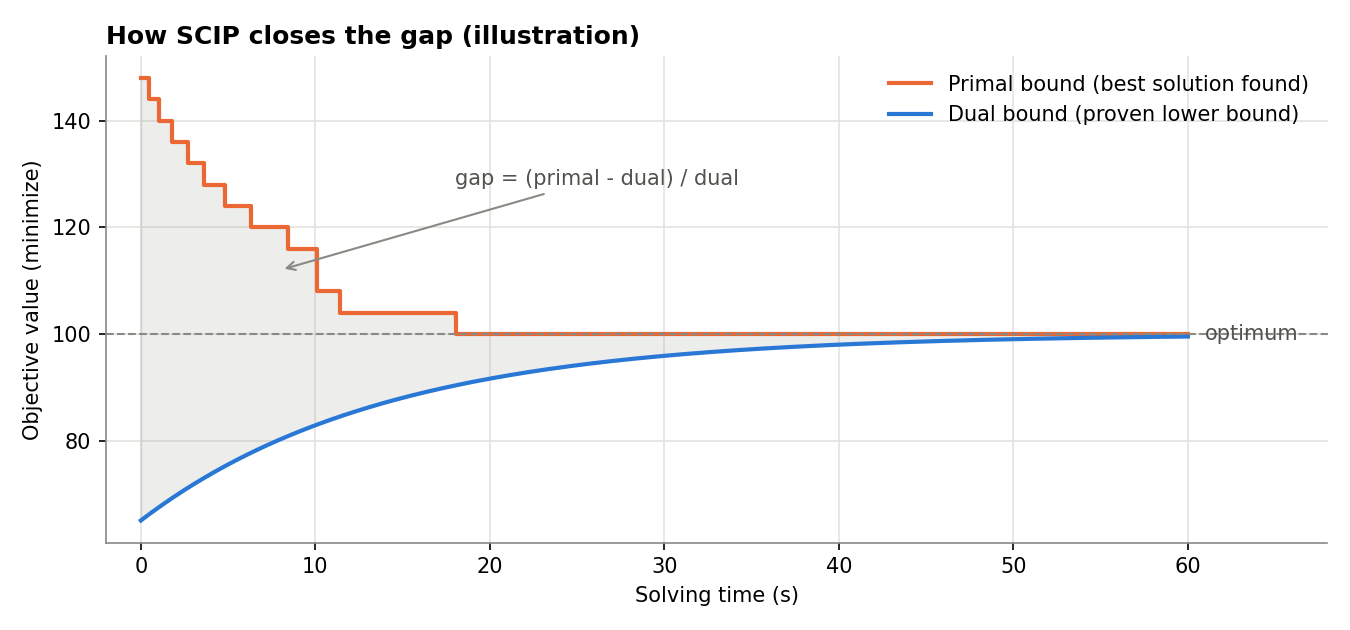

In [19]:
def plot_bounds_concept(path: Path) -> None:
    """Draw a stylized picture of how the primal and dual bounds close the gap, and save it as a PNG."""
    t = np.linspace(0, 60, 400)
    primal = 100 + 40 * np.exp(-t / 6) + np.where(t < 25, 8 * (t < 10), 0)
    primal = np.minimum.accumulate(np.round(primal / 4) * 4)       # incumbents improve in steps
    dual = 100 - 35 * np.exp(-t / 14)
    fig, ax = plt.subplots(figsize=(9, 4.2))
    ax.step(t, primal, where="post", color=ORANGE, lw=2, label="Primal bound (best solution found)")
    ax.plot(t, dual, color=BLUE, lw=2, label="Dual bound (proven lower bound)")
    ax.fill_between(t, dual, primal, step=None, color=GREY, alpha=0.15)
    ax.axhline(100, color=GREY, lw=1, ls="--")
    ax.text(61, 100, "optimum", va="center", color="#52514e")
    ax.set_xlim(-2, 68)
    ax.annotate("gap = (primal - dual) / dual", xy=(8, 112), xytext=(18, 128), color="#52514e",
                arrowprops={"arrowstyle": "->", "color": GREY})
    ax.set_xlabel("Solving time (s)")
    ax.set_ylabel("Objective value (minimize)")
    ax.set_title("How SCIP closes the gap (illustration)", loc="left", fontweight="bold")
    ax.legend(loc="upper right", frameon=False)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


plot_bounds_concept(FIGURES_DIR / "scip_bounds.png")
display(Image(filename=str(FIGURES_DIR / "scip_bounds.png")))

### A log with more to read

The basic model was too easy to show the progress table at work. The next run uses a richer model from 3.11: the solver **chooses the number of DCs**, each DC costs **0.6 M€ per year**, and at least **95 % of the demand** must arrive on time. Follow the primal and dual bounds line by line:
- presolve first shrinks the problem to about 500 variables;
- two heuristics find solutions before the LP is solved (`p`, *clique* and *vbounds*): the primal bound drops from 16.2 to 5.43 M€, while the dual bound is still negative, so the gap is `Inf`;
- after the root LP, the *farkasdiving* heuristic (`d`) finds a 4.65 M€ solution, and the dual bound rises to the same value: gap 0.00 %, optimal, at the root node, without any branching.

In [20]:
log_demo = build_greenfield_model(green_data, GreenfieldScenario(
    name="free number of DCs, 95% on time", n_dcs=None, fixed_cost_eur=600_000.0,
    sla_mode="min_service_level", min_service_level=0.95))
print("Status:", solve_model(log_demo.model))

presolving (10 rounds: 10 fast, 6 medium, 6 exhaustive):
 94 deleted vars, 94 deleted constraints, 0 added constraints, 0 tightened bounds, 0 added holes, 1 changed sides, 0 changed coefficients
 0 implications, 4956 cliques, 0 implied integral variables (0 bin, 0 int, 0 cont)
presolved problem has 5006 variables (5006 bin, 0 int, 0 cont) and 4957 constraints

 time | node  | left  |LP iter|LP it/n|mem/heur|mdpt |vars |cons |rows |cuts |sepa|confs|strbr|  dualbound   | primalbound  |  gap   | compl. 
p 3.7s|     1 |     0 |     0 |     - |  clique|   0 |5006 |4957 |4957 |   0 |  0 |   0 |   0 | 0.000000e+00 | 2.014255e+07 |    Inf | unknown
p 3.9s|     1 |     0 |     0 |     - | vbounds|   0 |5006 |4957 |4957 |   0 |  0 |   0 |   0 | 0.000000e+00 | 7.503446e+06 |    Inf | unknown
p 4.0s|     1 |     0 |    43 |     - | vbounds|   0 |5006 |5021 |4957 |   0 |  0 |  65 |   0 | 0.000000e+00 | 5.780900e+06 |    Inf | unknown
r 4.3s|     1 |     0 |  1558 |     - |rounding|   0 |5006 |5083 

<a id="sec-3-9"></a>
## 3.9 Center of gravity vs. optimization: the base model

Both approaches now answer the single-DC question. We compare them with the same KPIs, and then repeat the comparison for 1 to 5 DCs: the multi-DC center of gravity (weighted k-means, from 3.5) against the optimization model with $p$ = 1, ..., 5.

**What to look for**
- **One DC:** both answers cost the same (2.92 vs. 2.91 M€ per year). The center of gravity is a free point on the map, while the model must pick a real candidate
- **Service is poor either way:** fewer than half of the tons arrive on time (45 % to 46 %), because the big 2-hour customers. Neither method looks at the SLA yet; that comes in 3.10.
- **Two DCs:** the model is slightly cheaper (2.12 vs. 2.15 M€). It minimizes ton-kilometers, which is what we pay, while the center of gravity minimizes *squared* distances.
- **Three DCs or more:** the center of gravity looks cheaper, and with five DCs it even reaches 100 % on time while the model stays at 80 %. The reason is not a better method: k-means places DCs at **free points**, for example right next to Düsseldorf, while the model can only use our random candidate sites, and no site is close to Customer07. **The answer is only as good as the candidate list.**
- The center of gravity is a quick benchmark. The model gives a **buildable** answer, on real sites, with a **proof of optimality**, and it can include fixed costs and SLAs, as we see next.

,Center of gravity,Optimization (S100)
DCs,1.0,1.0
Transport cost (M€/year),2.9,2.9
Cost per ton (€/t),229.1,228.7
Average distance (km),217.0,215.9
Max distance (km),372.2,424.1
"Service level, customers (%)",70.0,66.0
"Service level, demand (%)",46.3,42.7


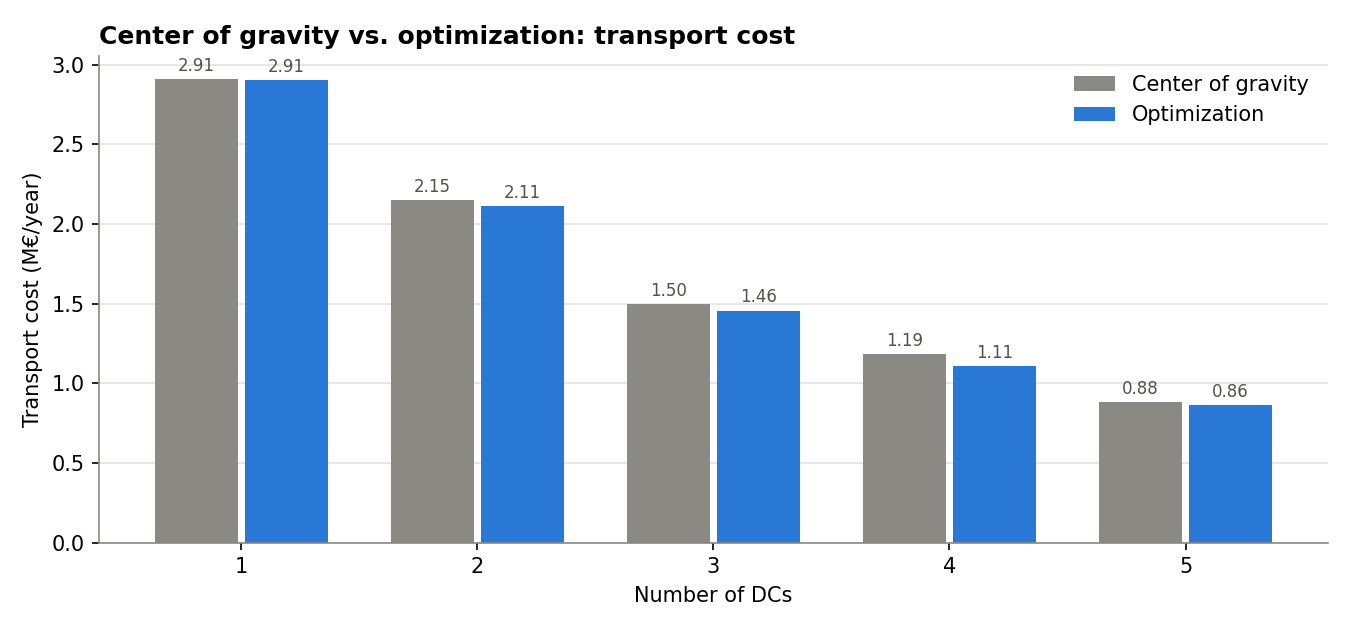

In [21]:
basic_sites = list(basic_row["Open sites"].split(", "))
single = pd.DataFrame({"Center of gravity": cog_kpis,
                       f"Optimization ({basic_sites[0]})": {k: basic_row[k] for k in cog_kpis}})
display(single.style.format("{:,.1f}"))


def compare_cog_vs_model(customers: pd.DataFrame, sites: pd.DataFrame, data: NetworkData,
                         max_dcs: int) -> pd.DataFrame:
    """Transport cost and service level of k-means centers vs. the p-median model, for 1..max_dcs DCs."""
    coords = customers[["Latitude", "Longitude"]].to_numpy()
    demand = customers["Demand"].to_numpy(float)
    rows: list[dict[str, float | str]] = []
    for k in range(1, max_dcs + 1):
        centers, group = weighted_kmeans(coords, demand, k=k)
        km_sites = pd.DataFrame(centers, columns=["Latitude", "Longitude"], index=[f"CoG {j + 1}" for j in range(k)])
        _, km = evaluate_assignment(customers, km_sites, {i: f"CoG {g + 1}" for i, g in zip(customers.index, group)})
        model_row, _ = run_greenfield(data, customers, sites, GreenfieldScenario(name=f"p={k}", n_dcs=k))
        for method, kpis in [("Center of gravity", km), ("Optimization", model_row)]:
            rows.append({"DCs": k, "Method": method, "Transport cost (M€/year)": kpis["Transport cost (M€/year)"],
                         "Service level, demand (%)": kpis["Service level, demand (%)"]})
    return pd.DataFrame(rows)


def plot_cog_vs_model(comparison: pd.DataFrame, path: Path) -> None:
    """Grouped bars of transport cost per number of DCs and method, saved as a PNG."""
    wide = comparison.pivot(index="DCs", columns="Method", values="Transport cost (M€/year)")
    fig, ax = plt.subplots(figsize=(9, 4.2))
    width = 0.38
    for offset, (method, color) in zip([-width / 2, width / 2], [("Center of gravity", GREY), ("Optimization", BLUE)]):
        bars = ax.bar(wide.index + offset, wide[method], width=width - 0.03, color=color, label=method)
        ax.bar_label(bars, fmt="%.2f", fontsize=8, color="#52514e", padding=2)
    ax.set_xlabel("Number of DCs")
    ax.set_ylabel("Transport cost (M€/year)")
    ax.set_xticks(wide.index)
    ax.set_title("Center of gravity vs. optimization: transport cost", loc="left", fontweight="bold")
    ax.legend(frameon=False)
    ax.grid(axis="x", visible=False)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


comparison = compare_cog_vs_model(customers, candidate_sites, green_data, max_dcs=5)
display(comparison.pivot(index="DCs", columns="Method").style.format("{:,.2f}"))
plot_cog_vs_model(comparison, FIGURES_DIR / "cog_vs_optimization.png")
display(Image(filename=str(FIGURES_DIR / "cog_vs_optimization.png")))

The map shows the optimal single DC. Compare it with the center-of-gravity map in 3.5: the DC moves about 90 km west, and the red circles are the customers that a single DC cannot reach within their SLA.

In [22]:
plot_solution_map(basic_detail, candidate_sites)

<a id="sec-3-10"></a>
## 3.10 Enforcing SLAs

So far the SLA was only *measured*. Now we make it a **hard constraint** (rule 4): no customer may be served late.

- With **one, two or three DCs**, look at the status: the model is **infeasible**, and SCIP proves it already in presolve.
- More DCs would not help: as we saw in 3.4, **Customer07 has no candidate site within 90 km**, so no network built from our candidate list can serve it on time.
- Infeasibility is an answer, not an error: *the business rules, as stated, cannot all hold.* The business must choose what to change: find a site near Düsseldorf, renegotiate this customer's SLA, or soften the rule (3.11).
- Notice how fast SCIP proves it: a hard rule that no site can satisfy for one customer is detected before any search starts.

In [23]:
sla_scenarios = [
    GreenfieldScenario(name="1 DC, hard SLA", n_dcs=1, sla_mode="hard"),
    GreenfieldScenario(name="2 DCs, cost only", n_dcs=2),
    GreenfieldScenario(name="2 DCs, hard SLA", n_dcs=2, sla_mode="hard"),
    GreenfieldScenario(name="3 DCs, cost only", n_dcs=3),
    GreenfieldScenario(name="3 DCs, hard SLA", n_dcs=3, sla_mode="hard"),
]
sla_rows: list[dict[str, float | str]] = []
sla_details: dict[str, pd.DataFrame | None] = {}
for scenario in sla_scenarios:
    row, detail = run_greenfield(green_data, customers, candidate_sites, scenario,
                                 show_log=scenario.name == "1 DC, hard SLA")
    sla_rows.append(row)
    sla_details[scenario.name] = detail
    print(f"{scenario.name:<18} -> status: {row['Status']}")

KPI_COLUMNS: list[str] = ["Status", "Open sites", "Transport cost (M€/year)", "Service level, customers (%)",
                          "Service level, demand (%)"]
display(pd.DataFrame([basic_row] + sla_rows).set_index("Scenario").reindex(columns=KPI_COLUMNS)
        .style.format(precision=2, na_rep="-"))

presolving (4 rounds: 4 fast, 2 medium, 2 exhaustive):
 4064 deleted vars, 2642 deleted constraints, 0 added constraints, 2596 tightened bounds, 0 added holes, 0 changed sides, 0 changed coefficients
 0 implications, 1063 cliques, 0 implied integral variables (0 bin, 0 int, 0 cont)
presolving detected infeasibility

SCIP Status        : problem is solved [infeasible]
Solving Time (sec) : 0.12
Solving Nodes      : 0
Primal Bound       : +1.00000000000000e+20 (0 solutions)
Dual Bound         : +1.00000000000000e+20
Gap                : 0.00 %
1 DC, hard SLA     -> status: infeasible
2 DCs, cost only   -> status: optimal
2 DCs, hard SLA    -> status: infeasible
3 DCs, cost only   -> status: optimal
3 DCs, hard SLA    -> status: infeasible


,Status,Open sites,Transport cost (M€/year),"Service level, customers (%)","Service level, demand (%)"
Scenario,,,,,
"1 DC, cost only",optimal,S100,2.91,66.00,42.70
"1 DC, hard SLA",infeasible,-,-,-,-
"2 DCs, cost only",optimal,"S47, S54",2.11,84.00,58.36
"2 DCs, hard SLA",infeasible,-,-,-,-
"3 DCs, cost only",optimal,"S47, S60, S82",1.46,88.00,66.16
"3 DCs, hard SLA",infeasible,-,-,-,-


Because every hard-SLA scenario is infeasible, there is no map to draw here. In 3.11 we soften the rule instead.

<a id="sec-3-11"></a>
## 3.11 Balancing costs and SLAs

A hard SLA is all or nothing, and here it is impossible. Managers usually ask a softer question: *how much does each extra point of service cost?* From now on, each DC costs **0.6 M€ per year** to run, and the solver may choose how many to open. We look at the question in three ways, each a small change to the same model, and we read each result right after it.

### Example A: how many DCs?

We fix the number of DCs from 1 to 5 and compare the total yearly bill: running cost plus transport. Then we switch rule 3 off and let the model choose the number itself.

In [24]:
DC_FIXED_COST_EUR: float = 600_000.0   # yearly cost of running one DC
COST_COLUMNS: list[str] = ["Status", "Open sites", "Fixed cost (M€/year)", "Transport cost (M€/year)",
                           "Total cost (M€/year)", "Service level, demand (%)"]


def number_of_dcs_sweep(data: NetworkData, customers: pd.DataFrame, sites: pd.DataFrame,
                        max_dcs: int, fixed_cost_eur: float) -> pd.DataFrame:
    """Total yearly cost (fixed + transport) and service for p = 1..max_dcs, plus the model's own choice of p."""
    scenarios = [GreenfieldScenario(name=f"{p} DCs", n_dcs=p, fixed_cost_eur=fixed_cost_eur) for p in range(1, max_dcs + 1)]
    scenarios.append(GreenfieldScenario(name="model chooses p", n_dcs=None, fixed_cost_eur=fixed_cost_eur))
    return pd.DataFrame([run_greenfield(data, customers, sites, s)[0] for s in scenarios]).set_index("Scenario")


dc_sweep = number_of_dcs_sweep(green_data, customers, candidate_sites, max_dcs=5, fixed_cost_eur=DC_FIXED_COST_EUR)
display(dc_sweep.reindex(columns=COST_COLUMNS).style.format(precision=2))

,Status,Open sites,Fixed cost (M€/year),Transport cost (M€/year),Total cost (M€/year),"Service level, demand (%)"
Scenario,,,,,,
1 DCs,optimal,S100,0.60,2.91,3.51,42.70
2 DCs,optimal,"S47, S54",1.20,2.11,3.31,58.36
3 DCs,optimal,"S47, S60, S82",1.80,1.46,3.26,66.16
4 DCs,optimal,"S06, S60, S72, S82",2.40,1.11,3.51,86.15
5 DCs,optimal,"S06, S60, S68, S72, S79",3.00,0.86,3.86,93.70
model chooses p,optimal,"S47, S60, S82",1.80,1.46,3.26,66.16


**Reading Example A**
- Total cost is **U-shaped**: 3.52 M€ with one DC, a minimum of **3.32 M€ with two DCs**, then 3.39, 3.64 and 3.99 M€.
- When the model chooses the number itself, it finds the same two-DC network.
- But that network delivers only **57 % of the demand on time**. The cheapest network is not the best served: cost alone would lead the business to a poor service level.

### Example B: a service target

We now ask for at least a share of the demand on time (rule 5) and let the model choose the number of DCs. Each row is the **cheapest** network that meets the target.

In [ ]:
def service_level_frontier(data: NetworkData, customers: pd.DataFrame, sites: pd.DataFrame,
                           fixed_cost_eur: float, levels: list[float]) -> pd.DataFrame:
    """Cheapest network (the model chooses the number of DCs) for each minimum share of demand on time."""
    rows = [run_greenfield(data, customers, sites,
                           GreenfieldScenario(name=f"at least {level:.0%} on time", n_dcs=None,
                                              fixed_cost_eur=fixed_cost_eur, sla_mode="min_service_level",
                                              min_service_level=level))[0] for level in levels]
    return pd.DataFrame(rows).set_index("Scenario")


frontier = service_level_frontier(green_data, customers, candidate_sites, fixed_cost_eur=DC_FIXED_COST_EUR,
                                  levels=[0.0, 0.70, 0.80, 0.90, 0.95, 1.0])
display(frontier.reindex(columns=COST_COLUMNS).style.format(precision=2))

**Reading Example B**
- Each step up in service costs one more DC: 72 % on time with three DCs (3.43 M€), 83 % with four (3.69 M€), 91 % with five (4.11 M€) and **96.6 %** with six (4.65 M€).
- **100 % is infeasible**, whatever we pay: Customer07 (3.4 % of the demand) cannot be reached in time from any candidate site.
- The curve gets steeper at the end: going from 57 % to 72 % costs 0.11 M€, while the last step from 91 % to 96.6 % costs 0.54 M€. This "flat, then steep" staircase is the typical shape of a cost/service trade-off.

### Example C: a penalty for late deliveries

Instead of a rule, we put a **price** on every late ton and let the model decide (the "fines" part of the bill). This is how many companies model contractual penalties or lost margin. The question becomes: *above which penalty does the model choose to serve everybody on time?*

In [ ]:
def penalty_sweep(data: NetworkData, customers: pd.DataFrame, sites: pd.DataFrame,
                  fixed_cost_eur: float, penalties: list[float]) -> pd.DataFrame:
    """Cheapest network (the model chooses the number of DCs) for each late-delivery penalty (€ per late ton)."""
    rows: list[dict[str, float | str]] = []
    for penalty in penalties:
        row, _ = run_greenfield(data, customers, sites,
                                GreenfieldScenario(name=f"penalty {penalty:.0f} €/t", n_dcs=None,
                                                   fixed_cost_eur=fixed_cost_eur, sla_mode="penalty",
                                                   late_penalty_eur_per_ton=penalty))
        rows.append(row)
    return pd.DataFrame(rows).set_index("Scenario")


penalties = penalty_sweep(green_data, customers, candidate_sites, fixed_cost_eur=DC_FIXED_COST_EUR,
                          penalties=[0, 50, 100, 250, 500, 2000])
display(penalties.reindex(columns=COST_COLUMNS).style.format(precision=2))

**Reading Example C**
- Up to 50 €/t, the model keeps the cheap two-DC network and pays the fines.
- From **100 €/t** it opens a third DC, and every higher penalty buys more DCs and more service: 85 % at 250 €/t, 94 % at 500 €/t, and the maximum 96.6 % at 2,000 €/t.
- Each penalty level matches a point of the staircase in Example B. The penalty at which the model switches is the **implicit value** of serving those customers on time, and a manager can compare it with the real cost of a late delivery: lost margin, contractual penalties, or a lost customer.

### The trade-offs in one picture

In [ ]:
def plot_tradeoffs(dc_sweep: pd.DataFrame, frontier: pd.DataFrame, path: Path) -> None:
    """Two panels: the cost split by number of DCs, and total cost vs. service target; saved as a PNG."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))

    fixed_only = dc_sweep.drop(index="model chooses p")
    p = np.arange(1, len(fixed_only) + 1)
    ax1.bar(p, fixed_only["Fixed cost (M€/year)"], color=GREY, width=0.6, label="Fixed cost")
    ax1.bar(p, fixed_only["Transport cost (M€/year)"], bottom=fixed_only["Fixed cost (M€/year)"] + 0.02,
            color=BLUE, width=0.6, label="Transport cost")
    top = fixed_only["Total cost (M€/year)"].max()
    for x, (_, r) in zip(p, fixed_only.iterrows()):
        ax1.text(x, r["Total cost (M€/year)"] + 0.03 * top,
                 f"{r['Total cost (M€/year)']:.2f} M€\n{r['Service level, demand (%)']:.0f}% on time",
                 ha="center", fontsize=8, color="#52514e")
    ax1.set_xticks(p)
    ax1.set_xlabel("Number of DCs")
    ax1.set_ylabel("Yearly cost (M€)")
    ax1.set_ylim(0, top * 1.38)
    ax1.set_title("A. More DCs: fixed vs. transport cost", loc="left", fontweight="bold")
    ax1.legend(frameon=False, loc="upper left", ncol=2)
    ax1.grid(axis="x", visible=False)

    ok = frontier[frontier["Status"] == "optimal"].drop_duplicates(subset=["Open sites"])
    ax2.plot(ok["Service level, demand (%)"], ok["Total cost (M€/year)"], color=BLUE, lw=2, marker="o", ms=8,
             mec="white", mew=2)
    for _, r in ok.iterrows():
        n_dcs = len(str(r["Open sites"]).split(", "))
        ax2.annotate(f"{n_dcs} DCs, {r['Total cost (M€/year)']:.2f} M€", xy=(r["Service level, demand (%)"],
                     r["Total cost (M€/year)"]), xytext=(0, 12), textcoords="offset points", ha="center",
                     fontsize=9, color="#52514e")
    ax2.set_xlabel("Demand delivered on time (%)")
    ax2.set_ylabel("Total cost (M€/year)")
    ax2.margins(x=0.12)
    ax2.set_ylim(ok["Total cost (M€/year)"].min() * 0.9, ok["Total cost (M€/year)"].max() * 1.05)
    ax2.set_title("B. The price of a service target", loc="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


plot_tradeoffs(dc_sweep, frontier, FIGURES_DIR / "sla_cost_tradeoff.png")
display(Image(filename=str(FIGURES_DIR / "sla_cost_tradeoff.png")))

**For the manager:** never report a single "optimal" network. Report the **cost curve** (left) and the **price of the service target** (right), and let the business choose, knowing the price of each step.

<a id="sec-3-12"></a>
## 3.12 Conclusion

- The **center of gravity** is a fast, intuitive first answer. It points to the right *region*, but it minimizes the wrong measure (squared distance), cannot choose among real sites, and knows nothing about SLAs or fixed costs.
- The **optimization model** answers the same question with the real cost, on real candidate sites, and with a **proof of optimality** that we can read in the SCIP log.
- Business rules become **constraints** (hard SLA), **objective terms** (penalties), or **parameters to sweep** (service level, number of DCs). Writing one function per rule keeps the model readable and lets us switch rules on and off per scenario.
- An **infeasible** model is a valuable answer: the rules, as stated, cannot all hold, and the business must choose what to relax. Here a single customer without a nearby candidate site made 100 % service impossible.
- The most useful output is not one network but a **trade-off curve** between cost and service.
- To go further: [Watson et al., 2013](#ref-watson) for network design in practice, [Montanher](#ref-montanher) for facility location, [Wolsey, 2020](#ref-wolsey) for the theory, [DeJans, 2025a](#ref-dejans-milp) and [DeJans, 2025b](#ref-dejans-lin) for modeling skills, and the [Gurobi, Burrito Optimization Game](#ref-burrito) to practice your intuition.

<a id="sec-3-13"></a>
## 3.13 Open questions

Discuss these in small groups, or try them in the code above.

1. **Assumptions drive answers.** Set `TRUCK_SPEED_KMH = 100` and `HANDLING_TIME_H = 0` instead: does the hard SLA become feasible, and with how many DCs? Which of the two assumptions would you validate first with the operations team?
2. **Squared vs. linear distance.** Why does the center of gravity minimize the *squared* distance? Construct a small example (three customers on a line) where the center of gravity and the 1-median are far apart.
3. **Candidate sites.** Our candidate sites are random points on land. Change `CANDIDATE_SITES` or `CANDIDATE_SEED` in 3.4 and re-run: can Customer07 be served on time now? does the optimal single DC move? Does the comparison with the center of gravity in 3.9 change? What is the risk of a list that is too short, and of one that is too long? How would you build a *realistic* list?
4. **Weak vs. strong linking.** Replace constraint (2) by the aggregated form $\sum_i x_{ij} \le |I|\, y_j$. Is the model still correct? Solve it with fixed costs and compare the log: number of nodes, dual bound at the root, solving time. Why does this happen? ([Wolsey, 2020](#ref-wolsey))
5. **Single sourcing.** We forced each customer to one DC ($x_{ij}$ binary). When would a company allow split deliveries, and how does the model change if $x_{ij}$ is the *share* of demand served by $j$?
6. **Service level definition.** We measured service as a share of **demand**. The two-DC network serves 80 % of the customers but only 57 % of the demand on time. Why so different? How would the results in 3.11 change if we measured service as a share of **customers**? Which definition would your sales team prefer, and which would your logistics team prefer?
7. **Penalty calibration.** In Example C, what is the business meaning of the penalty at which the model opens its third DC? Which data would you need to estimate a realistic penalty per late ton?
8. **Priorities.** The largest customers have the tightest SLA. Write a new constraint function that forces every customer above 500 t per year to be served on time, while the others are only penalized. How many DCs does the model open now?

<a id="sec-4"></a>
# 4. Further Reading

**Network design**
- <a id="ref-watson"></a>**[Watson et al., 2013]** Watson, M., Lewis, S., Cacioppi, P., & Jayaraman, J. (2013). *Supply Chain Network Design: Applying Optimization and Analytics to the Global Supply Chain*. Upper Saddle River, NJ: FT Press. ISBN 978-0-13-301737-3. An updated edition was published by Aspen Blue Publishing in 2017 with the subtitle *Understanding the Optimization behind Supply Chain Design Projects*.
- <a id="ref-montanher"></a>**[Montanher]** Montanher, T. de M. *Introduction to facility location*. LinkedIn article. <https://www.linkedin.com/pulse/introduction-facility-location-tiago-de-morais-montanher-phd-cap-tpf9f/>

**Integer programming**
- <a id="ref-wolsey"></a>**[Wolsey, 2020]** Wolsey, L. A. (2020). *Integer Programming* (2nd ed.). Hoboken, NJ: Wiley. ISBN 978-1-119-60653-6. The standard reference on formulations, relaxations, branch-and-bound and cutting planes, including why tight formulations such as $x_{ij} \le y_j$ matter.

**Hands-on modeling**
- <a id="ref-dejans-milp"></a>**[DeJans, 2025a]** DeJans Jr., A. D. (2025). *The MILP Optimization Handbook: An Introduction to Linear and Integer Programming for Practitioners*. Independently published. ISBN 9798294200862.
- <a id="ref-dejans-lin"></a>**[DeJans, 2025b]** DeJans Jr., A. D. (2025). *The Linearization Handbook for MILP Optimization: Modeling Tricks and Patterns for Practitioners*. Independently published. ISBN 9798293657544.

**Play with it**
- <a id="ref-burrito"></a>**[Gurobi, Burrito Optimization Game]** Gurobi Optimization. *The Burrito Optimization Game*. <https://www.gurobi.com/burrito-optimization-game/>. A browser game, designed with Larry Snyder (Lehigh University), in which you place burrito trucks to maximize profit, then compare your plan with the optimal one. It is a facility location problem in disguise, and a fun way to feel why optimization beats intuition.

**Tools used in this notebook**
- <a id="ref-scip"></a>**[SCIP]** SCIP Optimization Suite: <https://www.scipopt.org/> and PySCIPOpt: <https://github.com/scipopt/PySCIPOpt>.